In [15]:
# Cell 1: 导入 + 配置 / Imports & Config
import os, json
from collections import Counter
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

# Hardcoded absolute path (ipynb has no __file__; CWD may not be sae_code/)
SCRIPT_DIR = "/Users/elvainyu/Desktop/申请与学习/暑研和实习/暑研/‼️2026暑研资料/Computational Biology/Papers & Datas/SAE training/sae_code"
OUT_DIR = os.path.join(SCRIPT_DIR, "20260527_FP_Tree_v3a_Outputs")
os.makedirs(OUT_DIR, exist_ok=True)

# Sanity check: confirm files exist
print(f"SCRIPT_DIR exists: {os.path.exists(SCRIPT_DIR)}")
print(f"Files in SCRIPT_DIR matching sae_annotations*:")
for f in sorted(os.listdir(SCRIPT_DIR)):
    if f.startswith("sae_annotations"):
        print(f"  {f}")

LINEAGE_FILES = {
    "B-cell":  "sae_annotations_hybrid.json",
    "T/NK":    "sae_annotations_tcnk_routeB.json",
    "DC":      "sae_annotations_dc_routeB.json",
    "Mono":    "sae_annotations_mono_routeB.json",
}

PRIMARY_K   = 30
NAME_WEIGHT = 3
GENE_WEIGHT = 2

VARIANTS = [
    {"name": "v2_baseline",  "threshold": 3, "dominance": 0.70},
    {"name": "v3a_dom60",    "threshold": 3, "dominance": 0.60},
    {"name": "v3b_thresh4",  "threshold": 4, "dominance": 0.70},
    {"name": "v3c_strict",   "threshold": 4, "dominance": 0.60},
]

print("\nConfig loaded. Ready to load annotations.")

SCRIPT_DIR exists: True
Files in SCRIPT_DIR matching sae_annotations*:
  sae_annotations.json
  sae_annotations.xlsx
  sae_annotations_bcell_ttest.json
  sae_annotations_contrastive.json
  sae_annotations_dc_routeB.json
  sae_annotations_fewshot.json
  sae_annotations_hybrid.json
  sae_annotations_mono_routeB.json
  sae_annotations_rag.json
  sae_annotations_rag_ttest.json
  sae_annotations_table.xlsx
  sae_annotations_tcell_nk.json
  sae_annotations_tcnk_routeB.json

Config loaded. Ready to load annotations.


In [5]:
# Cell 2: 加载 4 谱系注释 / Load Lineage Annotations
def normalise_key_evidence(ev_list):
    genes = []
    for ev in ev_list[:5]:
        if isinstance(ev, str):
            genes.append(ev.split(":")[0].strip())
        elif isinstance(ev, dict):
            g = ev.get("gene", "") or ev.get("symbol", "")
            if g: genes.append(g)
    return [g for g in genes if g]

failure_names = {"api call failed", "annotation parse error", ""}
all_records   = []

for lineage, fname in LINEAGE_FILES.items():
    path = os.path.join(SCRIPT_DIR, fname)
    if not os.path.exists(path):
        print(f"  SKIP {lineage:<8}: file not found ({fname})")
        continue
    with open(path) as fh:
        records = json.load(fh)
    if isinstance(records, dict):
        records = list(records.values())
    n_kept = 0
    for r in records:
        name = r.get("programme_name", "")
        conf = r.get("confidence", "LOW")
        if name in failure_names or conf == "LOW":
            continue
        all_records.append({
            "lineage":                lineage,
            "feature_id":             r.get("feature_id"),
            "programme_name":         name,
            "functional_description": r.get("functional_description", ""),
            "top_genes_extracted":    normalise_key_evidence(r.get("key_evidence", [])),
        })
        n_kept += 1
    print(f"  {lineage:<8}: {n_kept:>4} kept")

print(f"\nTotal: {len(all_records)} programmes")

  B-cell  :  209 kept
  T/NK    :  150 kept
  DC      :  143 kept
  Mono    :  513 kept

Total: 1015 programmes


In [6]:
# Cell 3: TF-IDF + 层次聚类 / TF-IDF + Ward Clustering
def make_text(r):
    name_repeated  = (r["programme_name"] + " ") * NAME_WEIGHT
    desc           = r["functional_description"]
    genes_repeated = (" ".join(r["top_genes_extracted"]) + " ") * GENE_WEIGHT
    return f"{name_repeated}{desc} {genes_repeated}"

texts = [make_text(r) for r in all_records]
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.7, stop_words="english")
tfidf_matrix = vectorizer.fit_transform(texts)

sim_matrix  = cosine_similarity(tfidf_matrix).astype(np.float32)
dist_matrix = 1.0 - sim_matrix
np.fill_diagonal(dist_matrix, 0.0)
condensed   = squareform(dist_matrix, checks=False)
Z           = linkage(condensed, method="ward")
labels      = fcluster(Z, PRIMARY_K, criterion="maxclust")

for r, l in zip(all_records, labels):
    r["cluster"] = int(l)

# Precompute cluster stats once (reused by all variants)
cluster_ids   = sorted(set(r["cluster"] for r in all_records))
cluster_stats = {}
for cid in cluster_ids:
    cluster_records = [r for r in all_records if r["cluster"] == cid]
    lineage_counter = Counter(r["lineage"] for r in cluster_records)
    dominant, dom_n = lineage_counter.most_common(1)[0]
    dom_pct = dom_n / len(cluster_records)
    sample_names = list({r["programme_name"] for r in cluster_records})[:3]
    cluster_stats[cid] = {
        "n_programmes":         len(cluster_records),
        "n_lineages":           len(lineage_counter),
        "dominant_lineage":     dominant,
        "dominant_pct":         dom_pct,
        "lineage_distribution": "; ".join(f"{l}={n}" for l, n in lineage_counter.most_common()),
        "sample_programmes":    " | ".join(sample_names),
    }

print(f"TF-IDF: {tfidf_matrix.shape}")
print(f"Generated {len(cluster_ids)} clusters at k={PRIMARY_K}")
print(f"Cluster stats precomputed (reused by all variants below)")

TF-IDF: (1015, 8457)
Generated 30 clusters at k=30
Cluster stats precomputed (reused by all variants below)


In [7]:
# Cell 4: 4 变种对比 / Apply Each Variant & Compare
variant_assignments = {}
for v in VARIANTS:
    cluster_layers = {}
    for cid in cluster_ids:
        st = cluster_stats[cid]
        if st["n_lineages"] >= v["threshold"] and st["dominant_pct"] <= v["dominance"]:
            cluster_layers[cid] = "Ubiquitous"
        else:
            cluster_layers[cid] = f"{st['dominant_lineage']}-lineage"
    variant_assignments[v["name"]] = cluster_layers

n_total = len(all_records)
comparison_rows = []
for v in VARIANTS:
    layers              = variant_assignments[v["name"]]
    layer_counts        = Counter(layers[r["cluster"]] for r in all_records)
    cluster_layer_counts = Counter(layers.values())
    ubiq_prog           = layer_counts.get("Ubiquitous", 0)
    comparison_rows.append({
        "variant":           v["name"],
        "threshold (>=N)":   v["threshold"],
        "dominance (<=)":    f"{v['dominance']*100:.0f}%",
        "Ubiq programmes":   ubiq_prog,
        "Ubiq %":            round(100 * ubiq_prog / n_total, 1),
        "Ubiq clusters":     cluster_layer_counts.get("Ubiquitous", 0),
        "Mono-lineage":      layer_counts.get("Mono-lineage", 0),
        "B-cell-lineage":    layer_counts.get("B-cell-lineage", 0),
        "T/NK-lineage":      layer_counts.get("T/NK-lineage", 0),
        "DC-lineage":        layer_counts.get("DC-lineage", 0),
    })

df_compare = pd.DataFrame(comparison_rows)
df_compare.to_csv(os.path.join(OUT_DIR, "v3_variant_comparison.csv"), index=False)
df_compare   # 直接显示表格（ipynb 比 print 漂亮）

,variant,threshold (>=N),dominance (<=),Ubiq programmes,Ubiq %,Ubiq clusters,Mono-lineage,B-cell-lineage,T/NK-lineage,DC-lineage
0,v2_baseline,3,70%,163,16.1,3,468,191,135,58
1,v3a_dom60,3,60%,100,9.9,2,531,191,135,58
2,v3b_thresh4,4,70%,63,6.2,1,468,191,135,158
3,v3c_strict,4,60%,0,0.0,0,531,191,135,158


In [8]:
# Cell 5: 每个变种的 Ubiquitous Cluster 详情 / Ubiquitous Cluster Details
detail_rows = []
for v in VARIANTS:
    layers = variant_assignments[v["name"]]
    for cid in cluster_ids:
        if layers[cid] == "Ubiquitous":
            st = cluster_stats[cid]
            detail_rows.append({
                "variant":              v["name"],
                "cluster_id":           cid,
                "n_programmes":         st["n_programmes"],
                "n_lineages":           st["n_lineages"],
                "dominant_pct":         round(st["dominant_pct"] * 100, 1),
                "lineage_distribution": st["lineage_distribution"],
                "sample_programmes":    st["sample_programmes"],
            })

df_detail = pd.DataFrame(detail_rows)
df_detail.to_csv(os.path.join(OUT_DIR, "v3_ubiquitous_clusters.csv"), index=False)

# 按变种打印每个 Ubiquitous cluster
for v in VARIANTS:
    rows = [r for r in detail_rows if r["variant"] == v["name"]]
    print(f"\n=== {v['name']} ({len(rows)} Ubiquitous clusters) ===")
    for r in rows:
        print(f"  cluster {r['cluster_id']:>2}: n={r['n_programmes']:>3}, "
              f"lineages={r['n_lineages']}, dom={r['dominant_pct']:>4.1f}% "
              f"| {r['lineage_distribution']}")
        print(f"    e.g.: {r['sample_programmes'][:90]}")

df_detail   # 显示完整表格


=== v2_baseline (3 Ubiquitous clusters) ===
  cluster  1: n= 81, lineages=3, dom=51.9% | DC=42; Mono=36; B-cell=3
    e.g.: Antigen presentation and lysosomal homeostasis | MHC Class II Antigen Presentation | CD14 
  cluster 13: n= 63, lineages=4, dom=68.3% | Mono=43; B-cell=10; T/NK=6; DC=4
    e.g.: Mitochondrial oxidative metabolism GMP-ProMono | Mitochondrial OXPHOS in early erythroid p
  cluster 26: n= 19, lineages=3, dom=57.9% | DC=11; B-cell=7; Mono=1
    e.g.: Nuclear protein synthesis Pre-cDC | Cell cycle and mitotic progression | Proliferating pro

=== v3a_dom60 (2 Ubiquitous clusters) ===
  cluster  1: n= 81, lineages=3, dom=51.9% | DC=42; Mono=36; B-cell=3
    e.g.: Antigen presentation and lysosomal homeostasis | MHC Class II Antigen Presentation | CD14 
  cluster 26: n= 19, lineages=3, dom=57.9% | DC=11; B-cell=7; Mono=1
    e.g.: Nuclear protein synthesis Pre-cDC | Cell cycle and mitotic progression | Proliferating pro

=== v3b_thresh4 (1 Ubiquitous clusters) ===
  clus

,variant,cluster_id,n_programmes,n_lineages,dominant_pct,lineage_distribution,sample_programmes
0,v2_baseline,1,81,3,51.9,DC=42; Mono=36; B-cell=3,Antigen presentation and lysosomal homeostasis...
1,v2_baseline,13,63,4,68.3,Mono=43; B-cell=10; T/NK=6; DC=4,Mitochondrial oxidative metabolism GMP-ProMono...
2,v2_baseline,26,19,3,57.9,DC=11; B-cell=7; Mono=1,Nuclear protein synthesis Pre-cDC | Cell cycle...
3,v3a_dom60,1,81,3,51.9,DC=42; Mono=36; B-cell=3,Antigen presentation and lysosomal homeostasis...
4,v3a_dom60,26,19,3,57.9,DC=11; B-cell=7; Mono=1,Nuclear protein synthesis Pre-cDC | Cell cycle...
5,v3b_thresh4,13,63,4,68.3,Mono=43; B-cell=10; T/NK=6; DC=4,Mitochondrial oxidative metabolism GMP-ProMono...


In [9]:
#Cell 6 继续确定 v3a 为最终 layer 分配 + 给 all_records 打标签

# 选定 v3a (>=3 lineages, dominance <=60%) 作为最终版本
# 9.9% Ubiquitous + 2 clusters: MHC-II antigen presentation + Pre-cDC cell cycle

FINAL_VARIANT = "v3a_dom60"
final_layers  = variant_assignments[FINAL_VARIANT]

# 给每个 programme 打上 v3a 的 layer + cluster info
for r in all_records:
    cid = r["cluster"]
    r["fp_tree_layer"]   = final_layers[cid]
    r["fp_tree_cluster"] = cid

# Sanity check: 层级分布
from collections import Counter
final_layer_counts = Counter(r["fp_tree_layer"] for r in all_records)
print(f"Final layer assignment ({FINAL_VARIANT}):")
for layer, n in sorted(final_layer_counts.items(), key=lambda x: -x[1]):
    pct = 100 * n / len(all_records)
    print(f"  {layer:<25} {n:>4}  ({pct:.1f}%)")

# 同时给每个 cluster 加上代表性 sample programme（用于 sunburst hover）
for cid in cluster_ids:
    cluster_records = [r for r in all_records if r["cluster"] == cid]
    # 取 cluster 内最常见的程序名作为代表（如果有重复）
    name_counter = Counter(r["programme_name"] for r in cluster_records)
    top_name = name_counter.most_common(1)[0][0]
    cluster_stats[cid]["representative_name"] = top_name

print(f"\nAll {len(all_records)} programmes now tagged with fp_tree_layer + fp_tree_cluster.")
print(f"Cluster representative names assigned (for sunburst hover).")


Final layer assignment (v3a_dom60):
  Mono-lineage               531  (52.3%)
  B-cell-lineage             191  (18.8%)
  T/NK-lineage               135  (13.3%)
  Ubiquitous                 100  (9.9%)
  DC-lineage                  58  (5.7%)

All 1015 programmes now tagged with fp_tree_layer + fp_tree_cluster.
Cluster representative names assigned (for sunburst hover).


In [13]:
# Cell 7: 检查 Plotly + 构建 Sunburst 数据 / Check Plotly + Build Sunburst Data

# Check plotly install
try:
    import plotly
    import plotly.graph_objects as go
    print(f"Plotly OK (version: {plotly.__version__})")
except ImportError:
    raise ImportError(
        "Plotly not installed in scanpy-env.\n"
        "Run in terminal: /opt/miniconda3/envs/scanpy-env/bin/pip install plotly"
    )

# Layer colors
layer_colors = {
    "Ubiquitous":     "#FFD700",   # gold
    "B-cell-lineage": "#3498DB",   # blue
    "T/NK-lineage":   "#27AE60",   # green
    "DC-lineage":     "#8E44AD",   # purple
    "Mono-lineage":   "#FF6B35",   # orange
}

# Build flat hierarchy arrays for sunburst
ids       = []
labels    = []
parents   = []
values    = []
colors    = []
hovertext = []

TOTAL = len(all_records)

# Root node
ids.append("root")
labels.append(f"FP-Tree<br>{TOTAL} programmes")
parents.append("")
values.append(TOTAL)
colors.append("rgba(255,255,255,0)")
hovertext.append(f"<b>FP-Tree Root</b><br>All {TOTAL} programmes across 4 lineages")

# Layer nodes (ring 1)
for layer_name, color in layer_colors.items():
    layer_records = [r for r in all_records if r["fp_tree_layer"] == layer_name]
    if not layer_records:
        continue
    n = len(layer_records)
    ids.append(layer_name)
    labels.append(f"<b>{layer_name}</b><br>{n} ({100*n/TOTAL:.1f}%)")
    parents.append("root")
    values.append(n)
    colors.append(color)
    hovertext.append(f"<b>{layer_name}</b><br>{n} programmes ({100*n/TOTAL:.1f}% of total)")

# Cluster nodes (ring 2)
for cid in cluster_ids:
    cluster_records = [r for r in all_records if r["cluster"] == cid]
    layer = cluster_records[0]["fp_tree_layer"]
    st    = cluster_stats[cid]
    n     = len(cluster_records)

    rep_short = st["representative_name"][:25]
    if len(st["representative_name"]) > 25:
        rep_short += "..."

    ids.append(f"C{cid}")
    labels.append(f"C{cid}: {rep_short}<br>n={n}")
    parents.append(layer)
    values.append(n)
    colors.append(layer_colors[layer])
    hovertext.append(
        f"<b>Cluster {cid}</b> ({layer})<br>"
        f"n={n} programmes<br>"
        f"Lineages: {st['lineage_distribution']}<br>"
        f"Dominance: {st['dominant_pct']*100:.1f}%<br>"
        f"Top programme: {st['representative_name'][:80]}"
    )

print(f"\nBuilt sunburst hierarchy:")
print(f"  Root:         1 node")
print(f"  Layers:       {len(layer_colors)} nodes")
print(f"  Clusters:    {len(cluster_ids)} nodes")
print(f"  Total nodes: {len(ids)}")
print(f"\nReady to render in Cell 8.")

Plotly OK (version: 6.7.0)

Built sunburst hierarchy:
  Root:         1 node
  Layers:       5 nodes
  Clusters:    30 nodes
  Total nodes: 36

Ready to render in Cell 8.


In [16]:
# Cell 8: 渲染 Sunburst + 保存 HTML / Render Sunburst & Save HTML
fig = go.Figure(go.Sunburst(
    ids=ids,
    labels=labels,
    parents=parents,
    values=values,
    branchvalues="total",
    marker=dict(
        colors=colors,
        line=dict(color="rgba(0,0,0,0.3)", width=1),
    ),
    hovertext=hovertext,
    hoverinfo="text",
    insidetextorientation="radial",
    maxdepth=3,
    textfont=dict(size=10),
))

fig.update_layout(
    title=dict(
        text=(
            f"<b>FP-Decode Fingerprint Tree</b><br>"
            f"<sub>1015 programmes across 4 lineages | v3a: 9.9% Ubiquitous core</sub>"
        ),
        x=0.5,
        font=dict(size=18),
    ),
    width=900,
    height=900,
    margin=dict(t=80, l=20, r=20, b=20),
    paper_bgcolor="white",
)

# Display inline in notebook
fig.show()

# Save interactive HTML
html_path = os.path.join(OUT_DIR, "fp_tree_fingerprint_v3a.html")
fig.write_html(html_path)
print(f"Saved interactive HTML: {html_path}")

# Try PNG export (requires kaleido; skip silently if unavailable)
try:
    png_path = os.path.join(OUT_DIR, "fp_tree_fingerprint_v3a.png")
    fig.write_image(png_path, width=1200, height=1200, scale=2)
    print(f"Saved static PNG: {png_path}")
except Exception as e:
    print(f"PNG export skipped ({type(e).__name__}). Install kaleido or screenshot the HTML.")

Saved interactive HTML: /Users/elvainyu/Desktop/申请与学习/暑研和实习/暑研/‼️2026暑研资料/Computational Biology/Papers & Datas/SAE training/sae_code/20260527_FP_Tree_v3a_Outputs/fp_tree_fingerprint_v3a.html
PNG export skipped (ValueError). Install kaleido or screenshot the HTML.


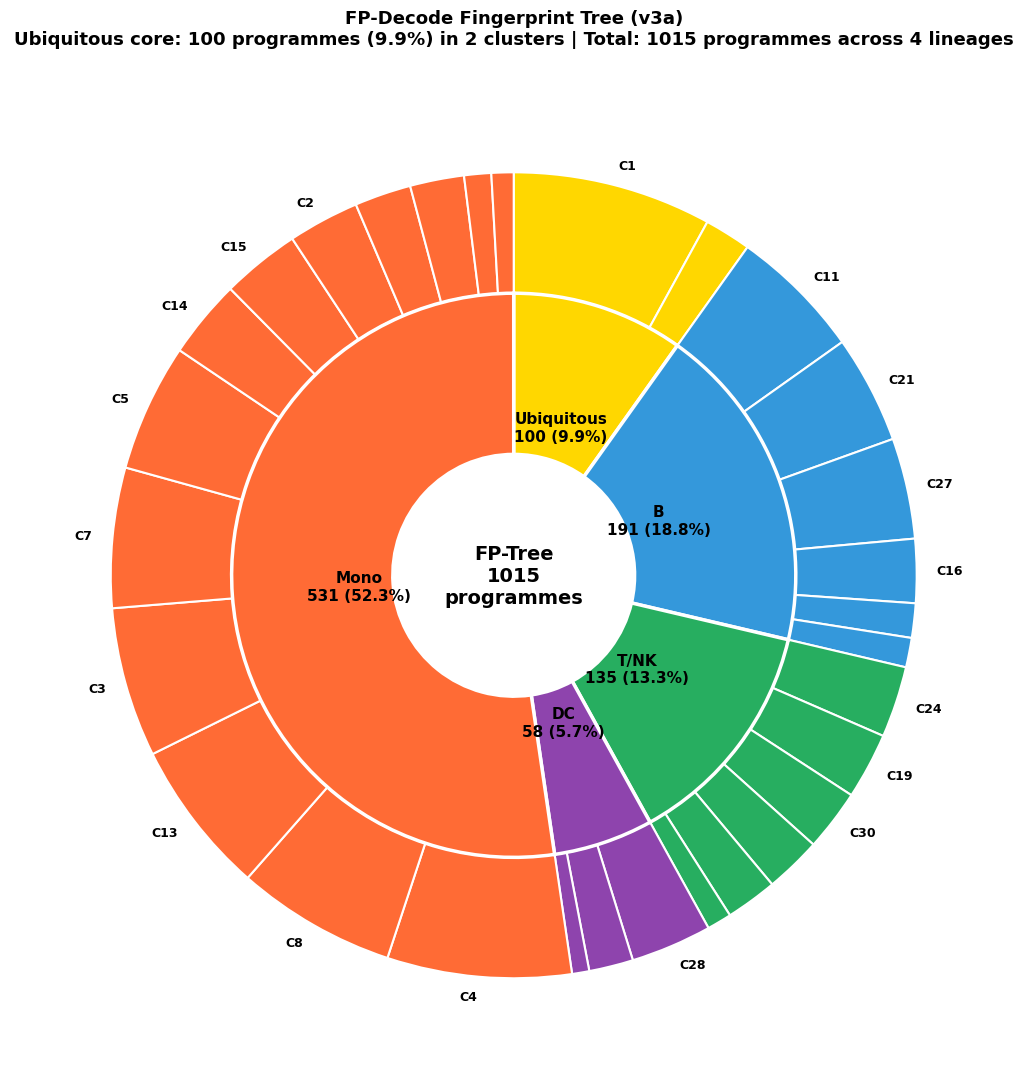


Saved static PNG: /Users/elvainyu/Desktop/申请与学习/暑研和实习/暑研/‼️2026暑研资料/Computational Biology/Papers & Datas/SAE training/sae_code/20260527_FP_Tree_v3a_Outputs/fp_tree_fingerprint_v3a_static.png


In [17]:
# Cell 9: 静态双环 Donut / Static 2-Ring Donut Backup
import matplotlib.pyplot as plt

layer_order = ["Ubiquitous", "B-cell-lineage", "T/NK-lineage", "DC-lineage", "Mono-lineage"]
inner_layer_counts = {l: 0 for l in layer_order}
for r in all_records:
    inner_layer_counts[r["fp_tree_layer"]] += 1

# === Inner ring (layers) ===
inner_sizes  = [inner_layer_counts[l] for l in layer_order]
inner_colors = [layer_colors[l] for l in layer_order]
inner_labels = [f"{l.split('-')[0]}\n{n} ({100*n/TOTAL:.1f}%)" for l, n in zip(layer_order, inner_sizes)]

# === Outer ring (clusters, grouped by layer) ===
outer_sizes  = []
outer_colors = []
outer_labels = []
for layer in layer_order:
    layer_clusters = sorted(
        [cid for cid in cluster_ids if final_layers[cid] == layer],
        key=lambda c: -cluster_stats[c]["n_programmes"],
    )
    for cid in layer_clusters:
        n = cluster_stats[cid]["n_programmes"]
        outer_sizes.append(n)
        outer_colors.append(layer_colors[layer])
        # Only label clusters with >= 25 programmes to avoid clutter
        outer_labels.append(f"C{cid}" if n >= 25 else "")

# === Render ===
fig, ax = plt.subplots(figsize=(11, 11))

# Outer ring (clusters)
ax.pie(
    outer_sizes,
    radius=1.0,
    colors=outer_colors,
    labels=outer_labels,
    labeldistance=1.05,
    wedgeprops=dict(width=0.3, edgecolor="white", linewidth=1.5),
    textprops=dict(fontsize=9, fontweight="bold"),
    startangle=90,
    counterclock=False,
)

# Inner ring (layers)
ax.pie(
    inner_sizes,
    radius=0.7,
    colors=inner_colors,
    labels=inner_labels,
    labeldistance=0.55,
    wedgeprops=dict(width=0.4, edgecolor="white", linewidth=2.5),
    textprops=dict(fontsize=11, fontweight="bold", ha="center"),
    startangle=90,
    counterclock=False,
)

# Center text
ax.text(
    0, 0,
    f"FP-Tree\n{TOTAL}\nprogrammes",
    ha="center", va="center", fontsize=14, fontweight="bold",
)

ax.set_title(
    f"FP-Decode Fingerprint Tree (v3a)\n"
    f"Ubiquitous core: {inner_layer_counts['Ubiquitous']} programmes (9.9%) in 2 clusters | "
    f"Total: {TOTAL} programmes across 4 lineages",
    fontsize=13, fontweight="bold", pad=20,
)

# Save
png_path = os.path.join(OUT_DIR, "fp_tree_fingerprint_v3a_static.png")
plt.tight_layout()
plt.savefig(png_path, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print(f"\nSaved static PNG: {png_path}")

In [18]:
# Cell 10: Fingerprint Tree 总结 / Fingerprint Tree Summary
print("=" * 70)
print("FP-DECODE FINGERPRINT TREE (v3a) — FINAL SUMMARY")
print("=" * 70)

print(f"\nTotal programmes:  {TOTAL}")
print(f"Source lineages:   B-cell, T/NK, DC, Mono")
print(f"Clusters (k=30):   {len(cluster_ids)}")

print(f"\n--- Layer Distribution ---")
for layer in layer_order:
    n = inner_layer_counts[layer]
    pct = 100 * n / TOTAL
    n_clusters_in_layer = sum(1 for cid in cluster_ids if final_layers[cid] == layer)
    print(f"  {layer:<20} {n:>4} programmes ({pct:>4.1f}%)  | {n_clusters_in_layer} clusters")

print(f"\n--- Ubiquitous Core (2 clusters, {inner_layer_counts['Ubiquitous']} programmes) ---")
ubiq_clusters = [cid for cid in cluster_ids if final_layers[cid] == "Ubiquitous"]
for cid in ubiq_clusters:
    st = cluster_stats[cid]
    print(f"  Cluster {cid:>2}: n={st['n_programmes']:>3}, "
          f"lineages={st['n_lineages']}, dom={st['dominant_pct']*100:>4.1f}%")
    print(f"    Distribution:   {st['lineage_distribution']}")
    print(f"    Representative: {st['representative_name']}")

print(f"\n--- Top 3 Clusters per Lineage ---")
for layer in ["B-cell-lineage", "T/NK-lineage", "DC-lineage", "Mono-lineage"]:
    layer_clusters = sorted(
        [cid for cid in cluster_ids if final_layers[cid] == layer],
        key=lambda c: -cluster_stats[c]["n_programmes"],
    )[:3]
    print(f"\n  {layer}:")
    for cid in layer_clusters:
        st = cluster_stats[cid]
        print(f"    C{cid}: n={st['n_programmes']:>3} | {st['representative_name'][:60]}")

print(f"\n--- Output Files ---")
print(f"  Folder: {OUT_DIR}")
for fname in sorted(os.listdir(OUT_DIR)):
    full = os.path.join(OUT_DIR, fname)
    size_kb = os.path.getsize(full) / 1024
    print(f"    {fname:<50} {size_kb:>8.1f} KB")

print(f"\n{'=' * 70}")
print(f"Fingerprint Tree work complete. Ready for Dr. Ng meeting.")
print(f"{'=' * 70}")

FP-DECODE FINGERPRINT TREE (v3a) — FINAL SUMMARY

Total programmes:  1015
Source lineages:   B-cell, T/NK, DC, Mono
Clusters (k=30):   30

--- Layer Distribution ---
  Ubiquitous            100 programmes ( 9.9%)  | 2 clusters
  B-cell-lineage        191 programmes (18.8%)  | 6 clusters
  T/NK-lineage          135 programmes (13.3%)  | 6 clusters
  DC-lineage             58 programmes ( 5.7%)  | 3 clusters
  Mono-lineage          531 programmes (52.3%)  | 13 clusters

--- Ubiquitous Core (2 clusters, 100 programmes) ---
  Cluster  1: n= 81, lineages=3, dom=51.9%
    Distribution:   DC=42; Mono=36; B-cell=3
    Representative: MHC Class II Antigen Presentation
  Cluster 26: n= 19, lineages=3, dom=57.9%
    Distribution:   DC=11; B-cell=7; Mono=1
    Representative: B-cell cycling with nucleosomal dynamics

--- Top 3 Clusters per Lineage ---

  B-cell-lineage:
    C11: n= 54 | Early erythroid mitochondrial oxidative phosphorylation
    C21: n= 44 | Mitochondrial biogenesis in early eryth